# Monte Carlo validation figures

Companion notebook for **"Stationary Analysis of Adaptive Aspiration Dynamics in
Graph-Structured Games"**.

The notebook reads the per-run CSV data produced by `src/simulate.c` (compile with
`make`, run with `make data`) and produces five publication figures:

| File | Content |
|---|---|
| `figure_weak_selection_mean.pdf` | Stationary mean: degree $k\in\{4,6,8\}$ (top row) and size $N\in\{20,50,100\}$ (bottom row) on random $k$-regular graphs |
| `figure_weak_selection_variance.pdf` | Same layout for the scaled stationary variance $N\,\mathrm{Var}_\beta(p_C)$ |
| `figure_topology_mean_comparison.pdf` | Stationary mean: averaged payoffs (top) and accumulated payoffs (bottom), with a common vertical range within each game |
| `figure_topology_variance_comparison.pdf` | Scaled variance: averaged payoffs (top) and accumulated payoffs (bottom), with a common vertical range within each game |
| `figure_learning_rate_strong_selection.pdf` | Learning rate $\rho\in\{0.1,0.5,1\}$ up to $\beta=4$ |

First-order predictions (Theorems 3.1 and 3.4):
$\mathbb{E}_\beta[p_C]=\tfrac12+\tfrac{\beta}{16}(R+S-T-P)+o(\beta)$ and
$N\,\mathrm{Var}_\beta(p_C)=\tfrac14+\tfrac{\beta}{32}\big[(R-S)-(T-P)\big]+o(\beta)$.
Markers are means over eight replications; where shown, error bars are one standard error.

**Plot customization.** All font sizes, font weights, title switches, frame switches,
line-connection switches, and panel-specific vertical ranges are collected in the
`USER-CONTROLLED PLOT SETTINGS` section of the first code cell.


## How to customize the figures

**Edit only the next code cell**, under `USER-CONTROLLED PLOT SETTINGS`.
The per-figure panel-height controls are followed by controls 1 to 9:

| Control | What to change |
|---|---|
| Figure and panel height | `FIGURE_WIDTH`, `SUBFIGURE_HEIGHTS` |
| 1. Legend | `LEGEND_FONT_SIZE`, `LEGEND_FONT_WEIGHT` |
| 2. Axis labels | `AXIS_LABEL_SIZE`, `AXIS_LABEL_WEIGHT` |
| 3. Axis numbers | `TICK_LABEL_SIZE`, `TICK_LABEL_WEIGHT` |
| 4. Text inside panels | `PARAMETER_TEXT_SIZE`, `PARAMETER_TEXT_WEIGHT` control the displayed $N$, $\rho$, and $k$ |
| 5. Main titles | `show_title` in `FIGURE_OPTIONS`, together with `MAIN_TITLE_STYLE` |
| 6. Panel subtitles | `show_subtitles` in `FIGURE_OPTIONS`, together with `SUBTITLE_STYLE` |
| 7. Boxes and error bars | `SHOW_AXES_BOX`, `SHOW_LEGEND_BOX`, `SHOW_PARAMETER_BOX`, `ERROR_BAR_OPTIONS` |
| 8. Vertical region | `PANEL_YLIMS` controls the other figures; `TOPOLOGY_COMPARISON_YLIMS` gives one common $y$-range to both payoff rows of each topology game |
| 9. Connecting segments | `connect_points` in `FIGURE_OPTIONS` |

For `PANEL_YLIMS`, the four columns are ordered as
**Donation, Snowdrift, Stag hunt, Harmony**. Use `None` for automatic
limits or `(minimum, maximum)` for fixed limits. For example,

```python
PANEL_YLIMS['learning_rate'][1][2] = (0.20, 0.40)
```

changes only row 1, column 2 of the learning-rate figure (Python counts
rows and columns from zero). Examples of other changes are

```python
FIGURE_OPTIONS['weak_mean']['show_title'] = False
FIGURE_OPTIONS['topology_mean_comparison']['connect_points'] = False
SUBFIGURE_HEIGHTS['topology_variance_comparison'] = 3.8
SUBTITLE_STYLE['topology_variance_comparison']['fontweight'] = 'bold'
PARAMETER_TEXT_SIZE = 8.5
```

The box switches refer to the axes frame, legend frame, and the white
background behind the parameter note; they do not create a statistical
box-and-whisker plot. The capped vertical marks are standard-error bars;
they are disabled by default for all variance panels.


For the new topology comparisons, one entry controls both the averaged and
accumulated rows of a game. For example,

```python
TOPOLOGY_COMPARISON_YLIMS['topology_mean_comparison'][2] = (0.40, 0.75)
```

assigns the same vertical region to both Stag-hunt mean panels. Leaving the
entry as `None` selects a common range automatically from both rows.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ======================================================================
# USER-CONTROLLED PLOT SETTINGS -- EDIT THIS SECTION ONLY
# ======================================================================

# General figure width and per-subfigure height, in inches.
# Each complete figure has two rows, so its total height is twice the
# corresponding SUBFIGURE_HEIGHTS value. Edit entries independently.
FIGURE_WIDTH = 12.4
SUBFIGURE_HEIGHTS = {
    'weak_mean': 3.4,
    'weak_variance': 3.4,
    'topology_mean_comparison': 3.4,
    'topology_variance_comparison': 3.4,
    'learning_rate': 3.4,
}

def figure_size(figure_key, nrows=2):
    '''Return the width and total height for one complete figure.'''
    return (FIGURE_WIDTH, nrows * SUBFIGURE_HEIGHTS[figure_key])

SAVE_DPI = 300              # resolution of saved PNG/PDF figures
BASE_FONT_SIZE = 8.5        # default font size for unclassified text

# ------------------------------------------------------------------
# CONTROL 1: SIZE AND THICKNESS OF ALL PLOT LEGENDS
# ------------------------------------------------------------------
LEGEND_FONT_SIZE = 9.5          # increase/decrease legend text size here
LEGEND_FONT_WEIGHT = 'normal'   # use 'normal', 'semibold', or 'bold'

# ------------------------------------------------------------------
# CONTROL 2: SIZE AND THICKNESS OF THE AXIS LABELS
# Examples: "Selection intensity beta" and "Stationary mean".
# ------------------------------------------------------------------
AXIS_LABEL_SIZE = 11.5
AXIS_LABEL_WEIGHT = 'normal'    # use 'normal', 'semibold', or 'bold'

# ------------------------------------------------------------------
# CONTROL 3: SIZE AND THICKNESS OF NUMBERS ON THE x- AND y-AXES
# ------------------------------------------------------------------
TICK_LABEL_SIZE = 9.0
TICK_LABEL_WEIGHT = 'normal'    # use 'normal', 'semibold', or 'bold'

# ------------------------------------------------------------------
# CONTROL 4: SIZE AND THICKNESS OF N, rho, AND k INSIDE THE PANELS
# ------------------------------------------------------------------
PARAMETER_TEXT_SIZE = 8.5
PARAMETER_TEXT_WEIGHT = 'normal'  # use 'normal', 'semibold', or 'bold'

# ------------------------------------------------------------------
# CONTROL 5: MAIN TITLE OF EACH COMPLETE FIGURE
# Set show_title=False in FIGURE_OPTIONS below to remove a main title.
# Change fontsize/fontweight here to style each main title separately.
# ------------------------------------------------------------------
MAIN_TITLE_STYLE = {
    'weak_mean':                    {'fontsize': 13.0, 'fontweight': 'bold'},
    'weak_variance':                {'fontsize': 13.0, 'fontweight': 'bold'},
    'topology_mean_comparison':     {'fontsize': 13.0, 'fontweight': 'bold'},
    'topology_variance_comparison': {'fontsize': 13.0, 'fontweight': 'bold'},
    'learning_rate':                {'fontsize': 13.0, 'fontweight': 'bold'},
}

# ------------------------------------------------------------------
# CONTROL 6: SUBTITLES ABOVE THE INDIVIDUAL GAME PANELS
# Each complete figure can have a different subtitle size and thickness.
# Set show_subtitles=False in FIGURE_OPTIONS to remove all subtitles
# from one complete figure.
# ------------------------------------------------------------------
SUBTITLE_STYLE = {
    'weak_mean':                    {'fontsize': 10.0, 'fontweight': 'normal'},
    'weak_variance':                {'fontsize': 10.0, 'fontweight': 'normal'},
    'topology_mean_comparison':     {'fontsize': 10.0, 'fontweight': 'normal'},
    'topology_variance_comparison': {'fontsize': 10.0, 'fontweight': 'normal'},
    'learning_rate':                {'fontsize': 10.0, 'fontweight': 'normal'},
}
SUBTITLE_PAD = 7                    # space between subtitle and panel
SHOW_PAYOFFS_IN_SUBTITLES = True    # False removes R,S,T,P from subtitles

# ------------------------------------------------------------------
# CONTROLS 5 AND 6 FOR EACH FIGURE
# show_title: add/remove the main title
# show_subtitles: add/remove game subtitles
# show_legend: add/remove the legend
# CONTROL 9: connect_points=True joins data dots by segments;
#            connect_points=False leaves the dots unconnected.
# ------------------------------------------------------------------
FIGURE_OPTIONS = {
    'weak_mean': {
        'show_title': True,
        'show_subtitles': True,
        'show_legend': True,
        'connect_points': False,
    },
    'weak_variance': {
        'show_title': True,
        'show_subtitles': True,
        'show_legend': True,
        'connect_points': False,
    },
    'topology_mean_comparison': {
        'show_title': True,
        'show_subtitles': True,
        'show_legend': True,
        'connect_points': True,
    },
    'topology_variance_comparison': {
        'show_title': True,
        'show_subtitles': True,
        'show_legend': True,
        'connect_points': True,
    },
    'learning_rate': {
        'show_title': True,
        'show_subtitles': True,
        'show_legend': True,
        'connect_points': False,
    },
}

# ------------------------------------------------------------------
# CONTROL 7: ADD OR REMOVE BOXES/FRAMES AND STANDARD-ERROR BARS
# SHOW_AXES_BOX=False removes only the top and right panel borders.
# SHOW_LEGEND_BOX controls the border around each legend.
# SHOW_PARAMETER_BOX controls the white box behind N, rho, and k.
# These switches do not create a statistical box-and-whisker plot.
# The vertical capped marks in the original figures are standard-error
# bars. They are disabled below for every variance panel.
# ------------------------------------------------------------------
SHOW_AXES_BOX = True
SHOW_LEGEND_BOX = True
SHOW_PARAMETER_BOX = True
ERROR_BAR_OPTIONS = {
    'weak_mean':            {'mean': True,  'nvar': False},
    'weak_variance':        {'mean': True,  'nvar': False},
    'topology_mean_comparison':     {'mean': True,  'nvar': False},
    'topology_variance_comparison': {'mean': True,  'nvar': False},
    'learning_rate':        {'mean': True,  'nvar': False},
}
# False removes the colored/shaded beta <= 0.5 background from Figure 5,
# so the full selection-intensity range has the same white background.
SHOW_WEAK_SELECTION_SHADE = False

# Optional marker, connecting-segment, and error-bar settings.
MARKER_SIZE = 3.8
MARKER_EDGE_WIDTH = 0.9
DATA_LINE_WIDTH = 0.8
DATA_LINE_ALPHA = 0.9
ERRORBAR_LINE_WIDTH = 0.8
ERRORBAR_CAP_SIZE = 1.8
ERRORBAR_CAP_THICKNESS = 0.8

# Horizontal plotting regions. Change these only if a different x-range
# is required for an entire figure.
X_LIMITS = {
    'weak_mean': (-0.015, 0.515),
    'weak_variance': (-0.015, 0.515),
    'topology_mean_comparison': (-0.015, 0.515),
    'topology_variance_comparison': (-0.015, 0.515),
    'learning_rate': (-0.1, 4.1),
}

# ------------------------------------------------------------------
# CONTROL 8: y-REGION PRINTED IN EVERY INDIVIDUAL SUBFIGURE
# Column order: [Donation, Snowdrift, Stag hunt, Harmony].
# Use None for automatic limits, or write (y_min, y_max).
# Example: (0.40, 0.52) instead of None fixes that one panel's y-range.
# ------------------------------------------------------------------
PANEL_YLIMS = {
    'weak_mean': [
        [None, None, None, None],  # row 0: degree k varies
        [None, None, None, None],  # row 1: population size N varies
    ],
    'weak_variance': [
    # Donation     Snowdrift     Stag hunt      Harmony
    [(0.21, 0.32), (0.21, 0.32), (0.21, 0.32), (0.21, 0.32)],  # k varies
    [(0.21, 0.32), (0.21, 0.32), (0.21, 0.32), (0.21, 0.32)],  # N varies
     ],
    'learning_rate': [
        [None, None, None, None],  # row 0: stationary mean
        [None, None, None, (0.16, 0.26)],  # row 1: scaled variance
    ],
}


# ------------------------------------------------------------------
# COMMON y-REGIONS FOR THE NEW TOPOLOGY COMPARISON FIGURES
# ------------------------------------------------------------------
# Column order: [Donation, Snowdrift, Stag hunt, Harmony].
# One entry is used for BOTH rows of the corresponding game.
# None chooses a common range automatically from averaged and accumulated
# data. Replace None by (y_min, y_max) to impose a common manual range.
TOPOLOGY_COMPARISON_YLIMS = {
    'topology_mean_comparison': [
        None, None, None, None,
    ],
    'topology_variance_comparison': [
        (0.12, 0.26), (0.1, 0.26), None, (0.15, 0.26),
    ],
}

# Examples (leave commented unless needed):
# TOPOLOGY_COMPARISON_YLIMS['topology_mean_comparison'][0] = (0.30, 0.55)
# TOPOLOGY_COMPARISON_YLIMS['topology_variance_comparison'][2] = (0.20, 0.50)

# Worked examples (leave commented unless you want these changes):
# FIGURE_OPTIONS['weak_mean']['show_title'] = False
# FIGURE_OPTIONS['topology_mean_comparison']['connect_points'] = False
# SUBFIGURE_HEIGHTS['topology_variance_comparison'] = 3.8
# SUBTITLE_STYLE['topology_variance_comparison']['fontweight'] = 'bold'
# PANEL_YLIMS['learning_rate'][1][2] = (0.20, 0.40)

# ----------------------------------------------------------------------
# Locations
# ----------------------------------------------------------------------
ROOT = Path('..') if Path('../data').exists() else Path('.')
DATA = ROOT / 'data'
FIGS = ROOT / 'figures'
FIGS.mkdir(exist_ok=True)

# ----------------------------------------------------------------------
# Global style
# ----------------------------------------------------------------------
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['DejaVu Serif'],
    'mathtext.fontset': 'cm',
    'font.size': BASE_FONT_SIZE,
    'axes.labelsize': AXIS_LABEL_SIZE,
    'axes.labelweight': AXIS_LABEL_WEIGHT,
    'legend.fontsize': LEGEND_FONT_SIZE,
    'xtick.labelsize': TICK_LABEL_SIZE,
    'ytick.labelsize': TICK_LABEL_SIZE,
    'axes.linewidth': 0.8,
    'savefig.bbox': 'tight',
    'figure.dpi': 130,
})

# ----------------------------------------------------------------------
# Games and first-order predictions
# ----------------------------------------------------------------------
GAMES = [
    ('donation',  'Donation game',  (1, -1, 2, 0)),
    ('snowdrift', 'Snowdrift game', (3,  2, 4, 0)),
    ('staghunt',  'Stag-hunt game', (3, -1, 0, 0)),
    ('harmony',   'Harmony game',   (3,  2, 1, 0)),
]

def payoff_label(RSTP):
    R, S, T, P = RSTP
    return rf'$R={R},\ S={S},\ T={T},\ P={P}$'

def mean_pred(beta, RSTP):
    R, S, T, P = RSTP
    return 0.5 + np.asarray(beta) * (R + S - T - P) / 16.0

def nvar_pred(beta, RSTP):
    R, S, T, P = RSTP
    return 0.25 + np.asarray(beta) * ((R - S) - (T - P)) / 32.0

def panel_title(idx, gname, RSTP):
    title = f'({chr(97 + idx)}) {gname}'
    return title + '\n' + payoff_label(RSTP) if SHOW_PAYOFFS_IN_SUBTITLES else title

# ----------------------------------------------------------------------
# Data loading and aggregation over the eight replications
# ----------------------------------------------------------------------
def load(name):
    return pd.read_csv(DATA / name)

def aggregate(df, keys):
    '''Replication mean and standard error of mean_pc and of N*var_pc.

    Uses named aggregation so the returned columns are exactly
    ``mean, mean_se, nvar, nvar_se, nrep``.
    Uses whatever number of replications each configuration actually has;
    prints a warning when this differs from the reference value of 8.
    '''
    import warnings
    df = df.copy()
    df['nvar'] = df['N'] * df['var_pc']

    def se(values):
        values = np.asarray(values, dtype=float)
        n = len(values)
        return values.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0

    g = df.groupby(list(keys), as_index=False).agg(
        mean=('mean_pc', 'mean'),
        mean_se=('mean_pc', se),
        nvar=('nvar', 'mean'),
        nvar_se=('nvar', se),
        nrep=('rep', 'size'),
    )
    g['nrep'] = g['nrep'].astype(int)
    rep_counts = sorted(g['nrep'].unique().tolist())
    if rep_counts != [8]:
        warnings.warn(
            f'aggregate(): replication counts across configurations = {rep_counts} '
            f'(reference: 8). Aggregating with the actual counts.', stacklevel=2)
    return g

df_kN   = load('weak_selection_kN.csv')
df_tavg = load('topology_averaged.csv')
df_tacc = load('topology_accumulated.csv')
df_rho  = load('learning_rate.csv')

print('rows:', {n: len(d) for n, d in
                [('kN', df_kN), ('topology averaged', df_tavg),
                 ('topology accumulated', df_tacc), ('learning rate', df_rho)]})


rows: {'kN': 3360, 'topology averaged': 2688, 'topology accumulated': 2688, 'learning rate': 3360}


In [2]:
# ----------------------------------------------------------------------
# Shared drawing helpers
# ----------------------------------------------------------------------
NEUTRAL_KW = dict(color='0.45', ls=':', lw=0.9, zorder=1)
PRED_KW    = dict(color='black', ls='-', lw=1.1, zorder=2)

def legend_style():
    '''Keyword arguments shared by panel and figure legends.'''
    kw = {
        'frameon': SHOW_LEGEND_BOX,
        'prop': {'size': LEGEND_FONT_SIZE, 'weight': LEGEND_FONT_WEIGHT},
    }
    if SHOW_LEGEND_BOX:
        kw.update(edgecolor='0.6', framealpha=1.0)
    return kw

def style_axis(ax):
    '''Apply tick-label fonts and add/remove the rectangular axes box.'''
    ax.tick_params(
        direction='in', which='both',
        top=SHOW_AXES_BOX, right=SHOW_AXES_BOX,
        length=3.2, width=0.7, labelsize=TICK_LABEL_SIZE,
    )
    for label in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
        label.set_fontweight(TICK_LABEL_WEIGHT)
    for side, spine in ax.spines.items():
        spine.set_linewidth(0.8)
        spine.set_visible(SHOW_AXES_BOX or side in ('left', 'bottom'))
    ax.xaxis.label.set_fontsize(AXIS_LABEL_SIZE)
    ax.xaxis.label.set_fontweight(AXIS_LABEL_WEIGHT)
    ax.yaxis.label.set_fontsize(AXIS_LABEL_SIZE)
    ax.yaxis.label.set_fontweight(AXIS_LABEL_WEIGHT)

def draw_series(ax, x, y, yerr, marker, color, label, every=2, line=False, show_error_bars=True):
    '''Draw open markers, optional connecting segments, and optional errors.'''
    if line:
        ax.plot(x, y, color=color, lw=DATA_LINE_WIDTH,
                alpha=DATA_LINE_ALPHA, zorder=3)
    ax.plot(x, y, marker=marker, ls='none', ms=MARKER_SIZE,
            mew=MARKER_EDGE_WIDTH, mfc='none', mec=color,
            label=label, zorder=4)
    if show_error_bars:
        ax.errorbar(
            x[::every], y[::every], yerr=yerr[::every], fmt='none',
            ecolor=color, elinewidth=ERRORBAR_LINE_WIDTH,
            capsize=ERRORBAR_CAP_SIZE, capthick=ERRORBAR_CAP_THICKNESS,
            zorder=3,
        )

def finish_grid(fig, axes, xlab=r'Selection intensity $\beta$'):
    for ax in axes[-1]:
        ax.set_xlabel(xlab)
    for row in axes:
        for ax in row:
            style_axis(ax)

def corner_note(ax, text, loc=None, ha='right', upper=False):
    '''Parameter note containing N, rho, and/or k.'''
    if loc is None:
        loc = (0.97, 0.90) if upper else (0.97, 0.05)
    bbox = None
    if SHOW_PARAMETER_BOX:
        bbox = dict(facecolor='white', edgecolor='none', alpha=0.85,
                    boxstyle='square,pad=0.15')
    ax.text(
        *loc, text, transform=ax.transAxes, ha=ha,
        va='top' if upper else 'bottom',
        fontsize=PARAMETER_TEXT_SIZE,
        fontweight=PARAMETER_TEXT_WEIGHT,
        color='0.35', zorder=5, bbox=bbox,
    )

def set_panel_subtitle(ax, figure_key, col, gkey, gname, RSTP):
    if FIGURE_OPTIONS[figure_key]['show_subtitles']:
        ax.set_title(panel_title(col, gname, RSTP),
                     pad=SUBTITLE_PAD, **SUBTITLE_STYLE[figure_key])
    else:
        ax.set_title('')

def add_main_title(fig, figure_key, text):
    '''Add the main title and return the top edge for tight_layout.'''
    if FIGURE_OPTIONS[figure_key]['show_title']:
        fig.suptitle(text, y=1.005, **MAIN_TITLE_STYLE[figure_key])
        return 0.99
    return 1.0

def apply_panel_ylim(ax, figure_key, row, col):
    '''Apply a user-specified y-region; None retains automatic scaling.'''
    limits = PANEL_YLIMS[figure_key][row][col]
    if limits is not None:
        if len(limits) != 2 or limits[0] >= limits[1]:
            raise ValueError(
                f'Invalid y-limits for {figure_key}, row {row}, column {col}: '
                f'{limits}. Use None or (y_min, y_max) with y_min < y_max.'
            )
        ax.set_ylim(*limits)

def trend_is_down(agg, mask, stat):
    '''True when the plotted series decrease over beta.'''
    d = agg[mask].sort_values('beta')
    bmin, bmax = d['beta'].min(), d['beta'].max()
    return d.loc[d['beta'] == bmax, stat].mean() < d.loc[d['beta'] == bmin, stat].mean()


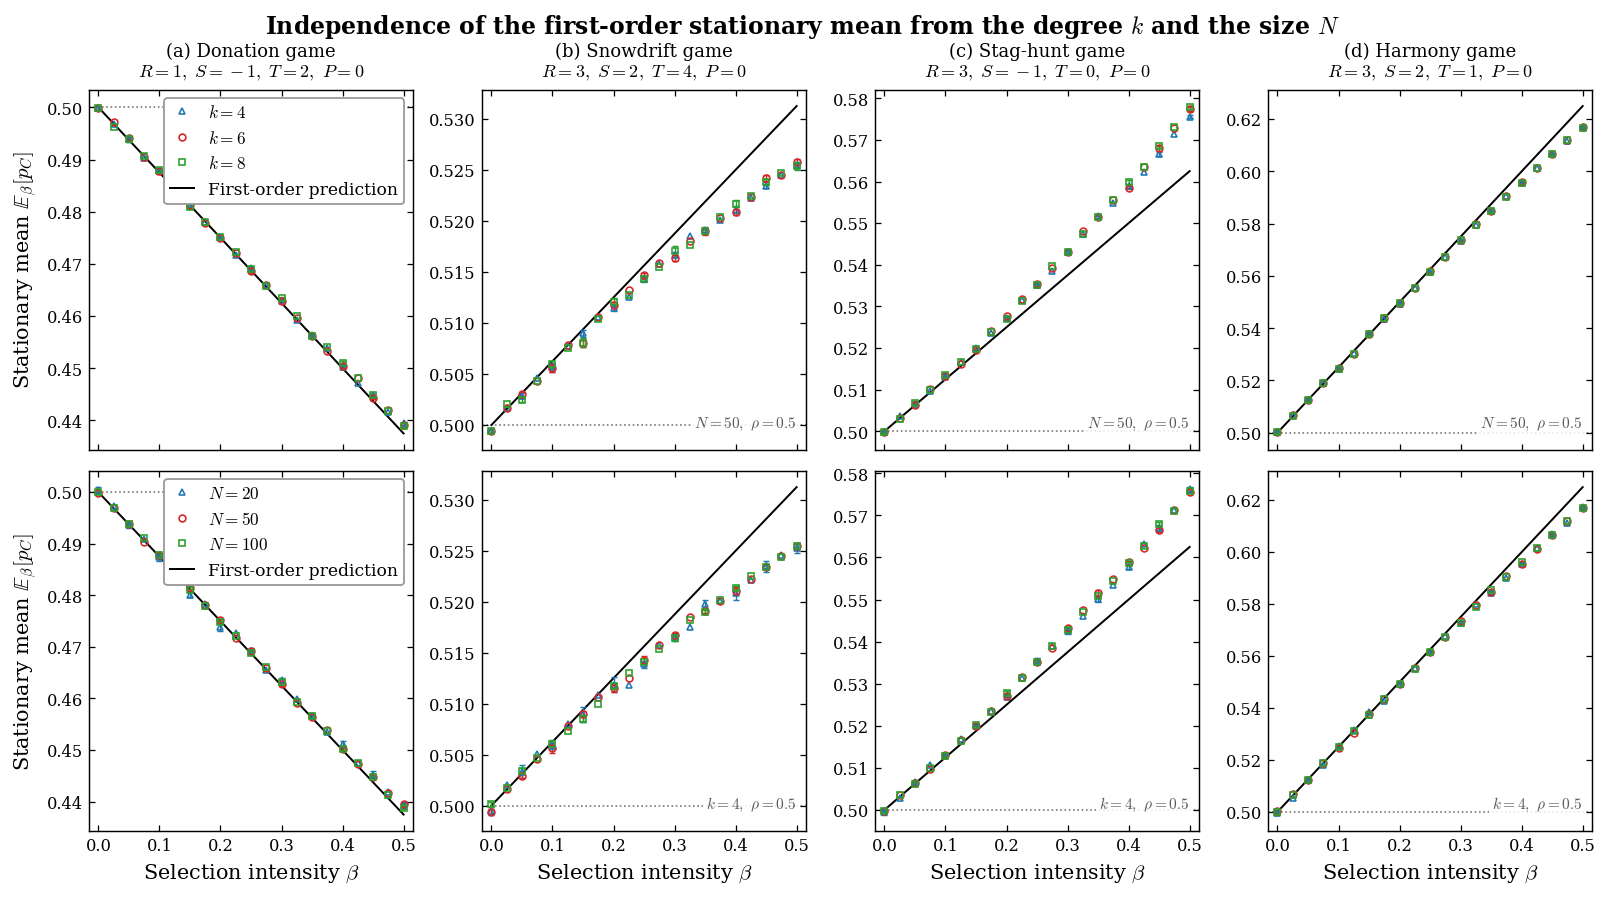

In [3]:
# FORMAT CONTROLS: edit FIGURE_OPTIONS['weak_mean'] or
# FIGURE_OPTIONS['weak_variance'], MAIN_TITLE_STYLE, SUBTITLE_STYLE,
# and the corresponding PANEL_YLIMS entry in the first code cell.
# ----------------------------------------------------------------------
# Figures 1 and 2: robustness of the weak-selection formulas to k and N
# on random k-regular graphs with averaged payoffs (rho = 0.5)
# ----------------------------------------------------------------------
K_SET = [(4, '^', '#1f77b4'), (6, 'o', '#d62728'), (8, 's', '#2ca02c')]
N_SET = [(20, '^', '#1f77b4'), (50, 'o', '#d62728'), (100, 's', '#2ca02c')]

def figure_weak_selection(stat, fname, suptitle):
    '''stat = "mean" (Theorem 3.1) or "nvar" (Theorem 3.4).'''
    figure_key = 'weak_mean' if stat == 'mean' else 'weak_variance'
    options = FIGURE_OPTIONS[figure_key]
    agg = aggregate(df_kN, ['game', 'N', 'k', 'beta'])
    fig, axes = plt.subplots(
        2, 4, figsize=figure_size(figure_key), sharex=True,
    )
    beta_line = np.linspace(0.0, 0.5, 201)
    pred = mean_pred if stat == 'mean' else nvar_pred
    neutral = 0.5 if stat == 'mean' else 0.25
    ylab = (r'Stationary mean $\mathbb{E}_\beta[p_C]$' if stat == 'mean'
            else r'Scaled variance $N\,\mathrm{Var}_\beta(p_C)$')

    for col, (gkey, gname, RSTP) in enumerate(GAMES):
        for row in range(2):
            ax = axes[row, col]
            sets = K_SET if row == 0 else N_SET
            for val, marker, color in sets:
                sel = ((agg['game'] == gkey) &
                       ((agg['k'] == val) & (agg['N'] == 50) if row == 0 else
                        (agg['N'] == val) & (agg['k'] == 4))).values
                d = agg[sel].sort_values('beta')
                lab = rf'$k = {val}$' if row == 0 else rf'$N = {val}$'
                draw_series(
                    ax, d['beta'].values, d[stat].values,
                    d[stat + '_se'].values, marker, color, lab,
                    line=options['connect_points'],
                    show_error_bars=ERROR_BAR_OPTIONS[figure_key][stat],
                )
            ax.axhline(neutral, **NEUTRAL_KW)
            ax.plot(beta_line, pred(beta_line, RSTP), **PRED_KW,
                    label='First-order prediction' if col == 0 else None)
            ax.set_xlim(*X_LIMITS[figure_key])
            if row == 0:
                set_panel_subtitle(ax, figure_key, col, gkey, gname, RSTP)
            note = (r'$N = 50,\ \rho = 0.5$' if row == 0
                    else r'$k = 4,\ \rho = 0.5$')
            corner_note(
                ax, note,
                upper=trend_is_down(
                    agg, (agg['game'] == gkey).values, stat),
            )
            apply_panel_ylim(ax, figure_key, row, col)
            if col == 0:
                ax.set_ylabel(ylab)
                if options['show_legend']:
                    ax.legend(
                        loc=('upper left' if
                             (stat == 'mean' and gkey != 'donation') else 'best'),
                        borderpad=0.35, handlelength=1.4, **legend_style(),
                    )

    finish_grid(fig, axes)
    top = add_main_title(fig, figure_key, suptitle)
    fig.tight_layout(rect=(0, 0, 1, top))
    for ext in ('pdf', 'png'):
        fig.savefig(FIGS / f'{fname}.{ext}', dpi=SAVE_DPI)
    plt.show()

figure_weak_selection(
    'mean', 'figure_weak_selection_mean',
    r'Independence of the first-order stationary mean from the degree $k$ and the size $N$')


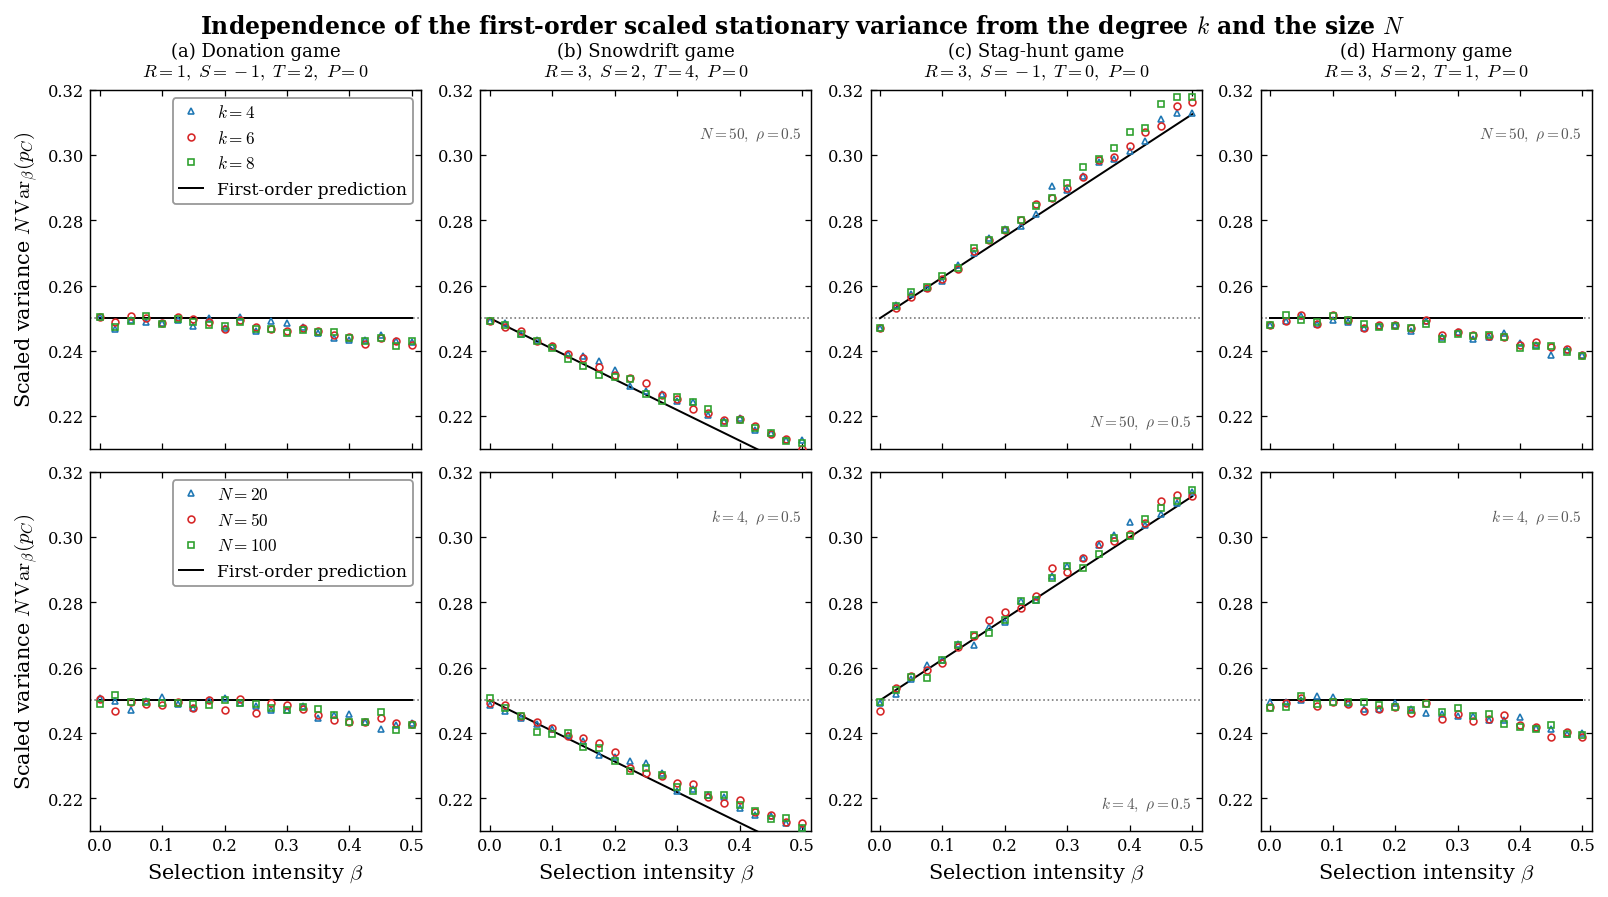

In [4]:
# FORMAT CONTROLS FOR THIS FIGURE: use the 'weak_variance' entries
# in FIGURE_OPTIONS, MAIN_TITLE_STYLE, and PANEL_YLIMS above.
figure_weak_selection(
    'nvar', 'figure_weak_selection_variance',
    r'Independence of the first-order scaled stationary variance from the degree $k$ and the size $N$')


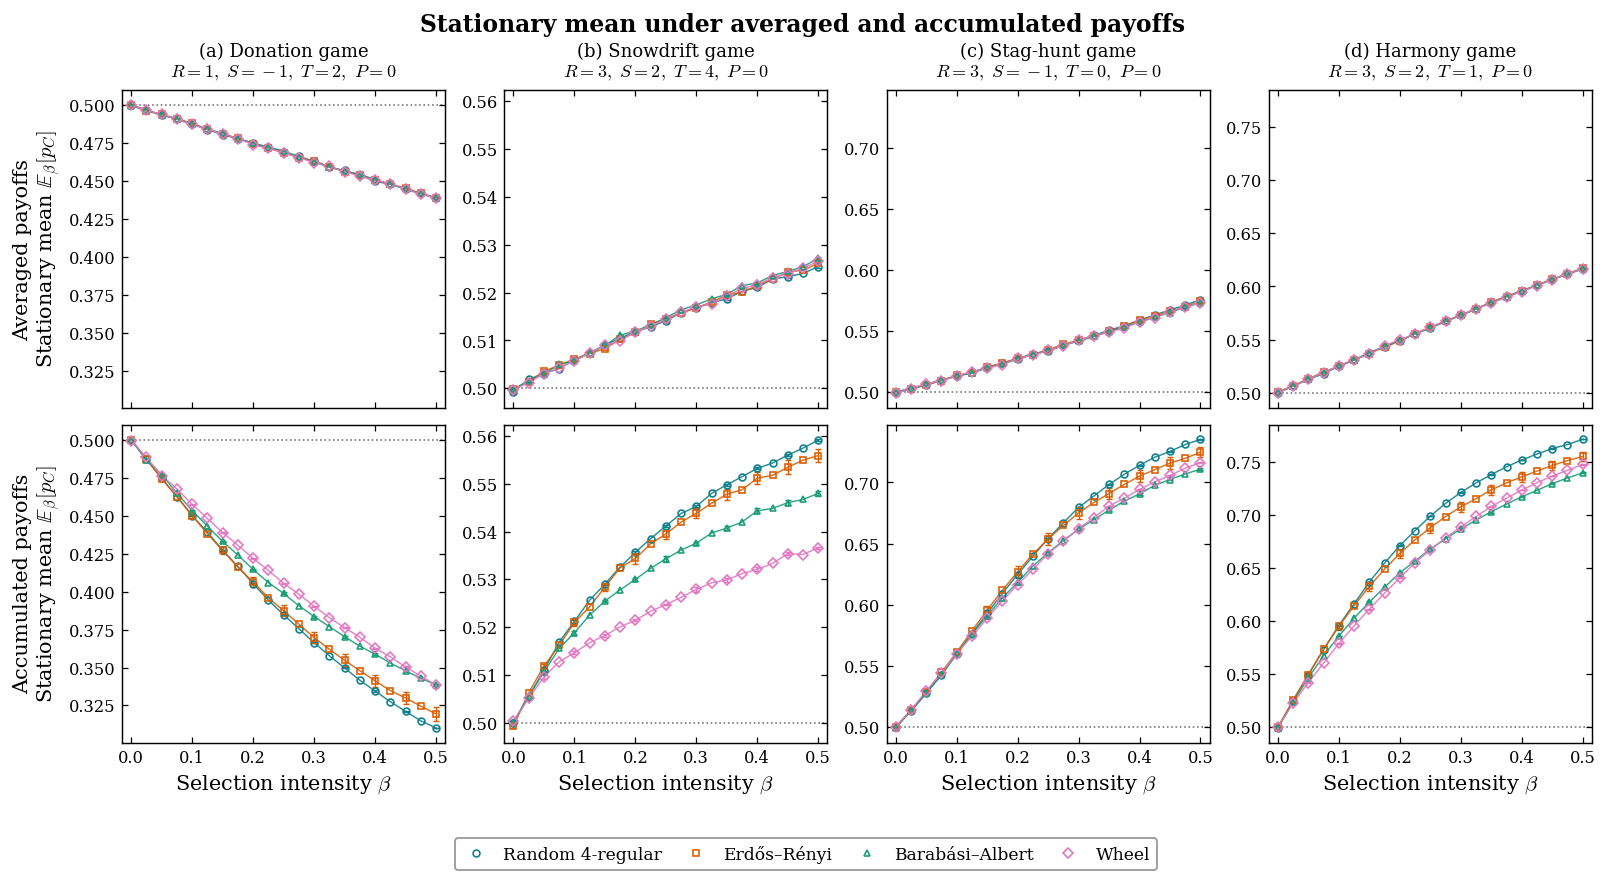

In [5]:
# ----------------------------------------------------------------------
# Figures 3 and 4: direct comparison of averaged and accumulated payoffs
# Top row: averaged payoffs; bottom row: accumulated payoffs
# N = 50 and rho = 0.5
# ----------------------------------------------------------------------

TOPO_SET = [
    # graph key          marker  color      legend label
    ('regular',          'o',    '#0f7f8b', 'Random 4-regular'),
    ('erdos_renyi',      's',    '#d95f02', 'Erdős–Rényi'),
    ('barabasi_albert',  '^',    '#1b9e77', 'Barabási–Albert'),
    ('wheel',            'D',    '#e377c2', 'Wheel'),
]

# Legend placement. The legend remains inside the canvas.
TOPOLOGY_LEGEND_Y = 0.015
TOPOLOGY_BOTTOM_MARGIN = 0.10

# Size and thickness of N and rho inside the panels.
TOPOLOGY_NOTE_SIZE = 10.0
TOPOLOGY_NOTE_WEIGHT = 'normal'
TOPOLOGY_NOTE_COLOR = '0.20'


def figure_topology_comparison(
    df_averaged,
    df_accumulated,
    stat,
    fname,
    suptitle,
    figure_key,
):
    '''Compare averaged (top) and accumulated (bottom) payoffs.

    stat='mean' produces Figure 3 and stat='nvar' produces Figure 4.
    sharey='col' guarantees identical y-limits for the two payoff rows
    within each game column.
    '''
    if stat not in ('mean', 'nvar'):
        raise ValueError("stat must be 'mean' or 'nvar'")

    options = FIGURE_OPTIONS[figure_key]
    agg_averaged = aggregate(df_averaged, ['game', 'graph', 'beta'])
    agg_accumulated = aggregate(df_accumulated, ['game', 'graph', 'beta'])

    payoff_rows = [
        ('Averaged payoffs', agg_averaged),
        ('Accumulated payoffs', agg_accumulated),
    ]

    # sharey='col' is the key comparison constraint: the two rows of each
    # game always use the same vertical region, either automatic or manual.
    fig, axes = plt.subplots(
        2, 4,
        figsize=figure_size(figure_key),
        sharex=True,
        sharey='col',
    )

    neutral_value = 0.5 if stat == 'mean' else 0.25
    statistic_label = (
        r'Stationary mean $\mathbb{E}_\beta[p_C]$'
        if stat == 'mean'
        else r'Scaled variance $N\,\mathrm{Var}_\beta(p_C)$'
    )

    for col, (gkey, gname, RSTP) in enumerate(GAMES):
        for row, (payoff_label_text, agg) in enumerate(payoff_rows):
            ax = axes[row, col]

            for graph, marker, color, label in TOPO_SET:
                selected = (
                    (agg['game'] == gkey)
                    & (agg['graph'] == graph)
                )
                data = agg[selected].sort_values('beta')

                draw_series(
                    ax,
                    data['beta'].values,
                    data[stat].values,
                    data[stat + '_se'].values,
                    marker,
                    color,
                    label,
                    line=options['connect_points'],
                    show_error_bars=ERROR_BAR_OPTIONS[figure_key][stat],
                )

            ax.axhline(neutral_value, **NEUTRAL_KW)

            ax.set_xlim(*X_LIMITS[figure_key])

            if row == 0:
                set_panel_subtitle(
                    ax, figure_key, col, gkey, gname, RSTP,
                )

            if col == 0:
                ax.set_ylabel(
                    payoff_label_text + '\n' + statistic_label
                )

        # A single optional y-range is applied to both payoff rows.
        limits = TOPOLOGY_COMPARISON_YLIMS[figure_key][col]
        if limits is not None:
            if len(limits) != 2 or limits[0] >= limits[1]:
                raise ValueError(
                    f'Invalid shared y-limits for {figure_key}, column {col}: '
                    f'{limits}. Use None or (y_min, y_max).'
                )
            axes[0, col].set_ylim(*limits)

    finish_grid(fig, axes)
    # Show y-axis numbers in both rows despite the shared y-axis.
    for axis_row in axes:
        for ax in axis_row:
            ax.tick_params(labelleft=True)

    top = add_main_title(fig, figure_key, suptitle)
    bottom = TOPOLOGY_BOTTOM_MARGIN if options['show_legend'] else 0.0
    fig.tight_layout(rect=(0, bottom, 1, top))

    if options['show_legend']:
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc='lower center',
            ncol=len(labels),
            bbox_to_anchor=(0.5, TOPOLOGY_LEGEND_Y),
            handlelength=1.6,
            columnspacing=1.2,
            **legend_style(),
        )

    for extension in ('pdf', 'png'):
        fig.savefig(
            FIGS / f'{fname}.{extension}',
            dpi=SAVE_DPI,
        )
    plt.show()


# ----------------------------------------------------------------------
# Generate Figure 3: stationary mean
# Top row = averaged payoffs; bottom row = accumulated payoffs
# ----------------------------------------------------------------------
figure_topology_comparison(
    df_tavg,
    df_tacc,
    stat='mean',
    fname='figure_topology_mean_comparison',
    suptitle='Stationary mean under averaged and accumulated payoffs',
    figure_key='topology_mean_comparison',
)


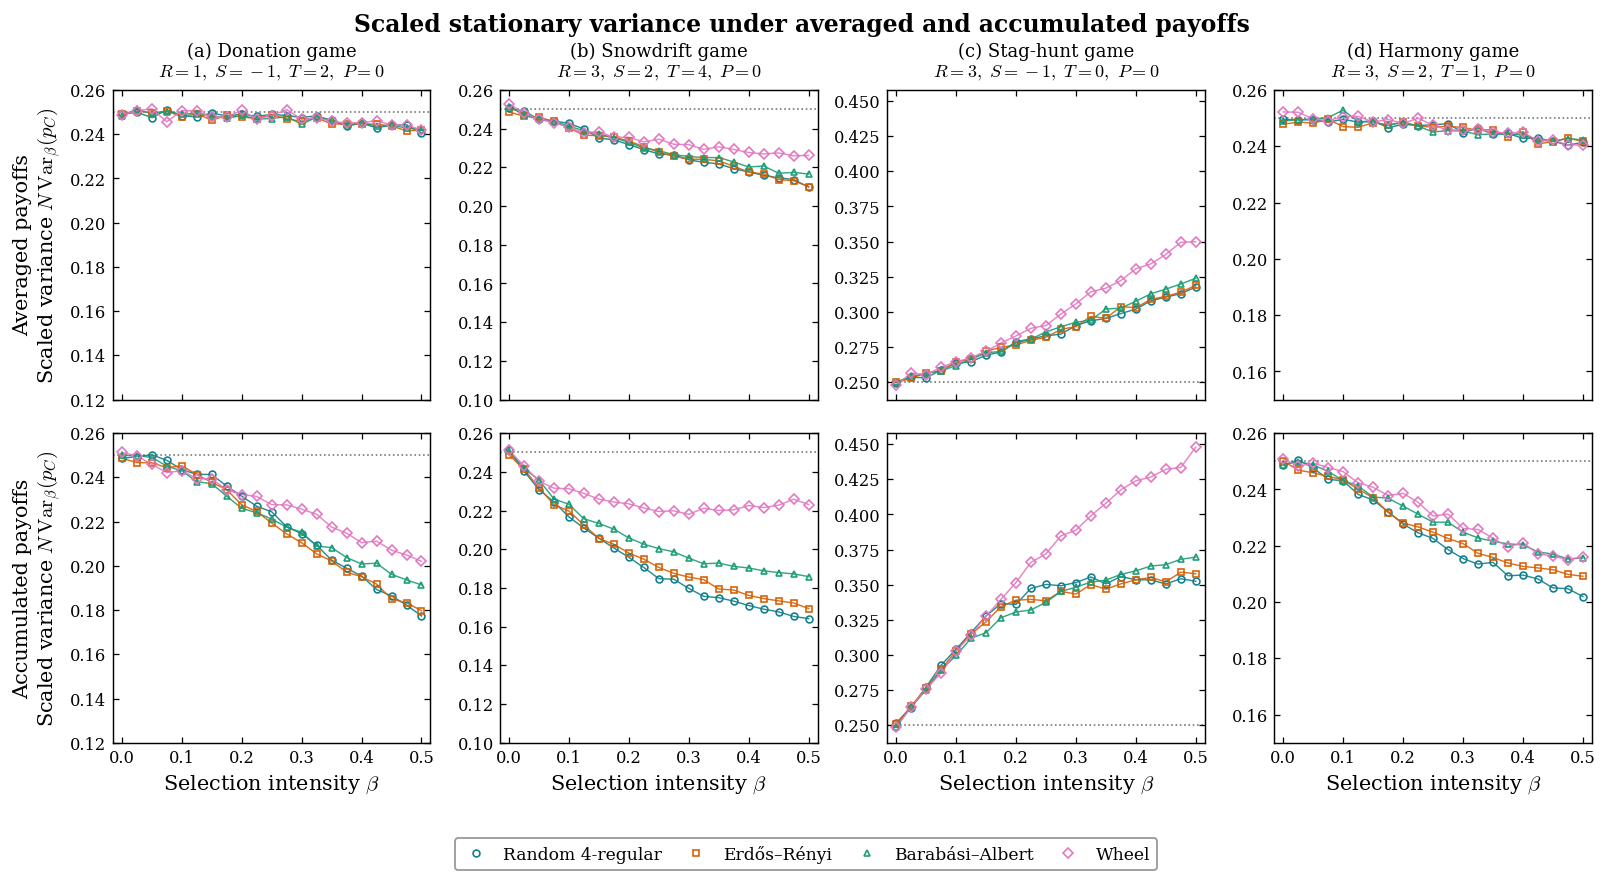

In [6]:
# ----------------------------------------------------------------------
# Generate Figure 4: scaled stationary variance
# Top row = averaged payoffs; bottom row = accumulated payoffs
# ----------------------------------------------------------------------
figure_topology_comparison(
    df_tavg,
    df_tacc,
    stat='nvar',
    fname='figure_topology_variance_comparison',
    suptitle='Scaled stationary variance under averaged and accumulated payoffs',
    figure_key='topology_variance_comparison',
)


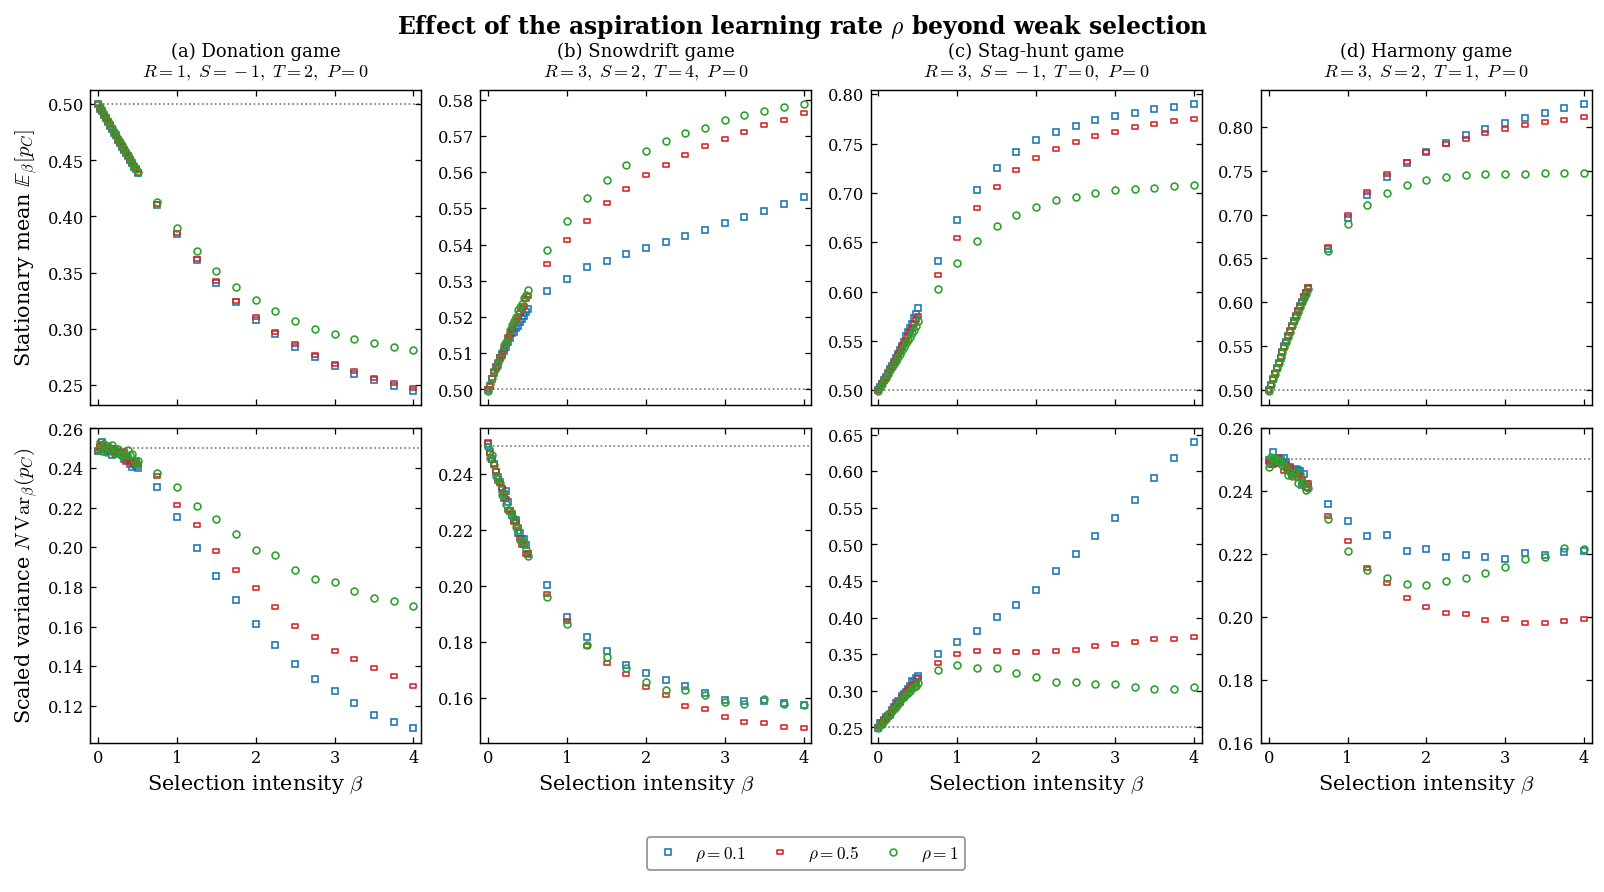

In [7]:
# FORMAT CONTROLS: use the 'learning_rate' entries in FIGURE_OPTIONS,
# MAIN_TITLE_STYLE, and PANEL_YLIMS in the first code cell.
# ----------------------------------------------------------------------
# Figure 5: the learning rate beyond weak selection
# (random 4-regular graphs, averaged payoffs, N = 50, beta up to 4)
# ----------------------------------------------------------------------

from matplotlib.path import Path

# Custom horizontal rectangle marker
RECTANGLE_MARKER = Path(
    [
        (-1.0, -0.55),
        ( 1.0, -0.55),
        ( 1.0,  0.55),
        (-1.0,  0.55),
        (-1.0, -0.55),
    ],
    [
        Path.MOVETO,
        Path.LINETO,
        Path.LINETO,
        Path.LINETO,
        Path.CLOSEPOLY,
    ],
)

# Square, rectangle, and circle
RHO_SET = [
    (0.1, 's',              '#1f77b4'),
    (0.5, RECTANGLE_MARKER, '#d62728'),
    (1.0, 'o',              '#2ca02c'),
]

# Figure-level legend placement, matching Figures 3 and 4
LEARNING_RATE_LEGEND_Y = 0.015
LEARNING_RATE_BOTTOM_MARGIN = 0.10


def figure_learning_rate():
    figure_key = 'learning_rate'
    options = FIGURE_OPTIONS[figure_key]

    agg = aggregate(df_rho, ['game', 'rho', 'beta'])

    fig, axes = plt.subplots(
        2, 4,
        figsize=figure_size(figure_key),
        sharex=True,
    )

    for col, (gkey, gname, RSTP) in enumerate(GAMES):
        for row, stat in enumerate(('mean', 'nvar')):
            ax = axes[row, col]

            if SHOW_WEAK_SELECTION_SHADE:
                ax.axvspan(
                    0.0, 0.5,
                    color='0.88',
                    zorder=0,
                )

            for rho, marker, color in RHO_SET:
                sel = (
                    (agg['game'] == gkey)
                    & np.isclose(agg['rho'], rho)
                )

                d = agg[sel].sort_values('beta')

                draw_series(
                    ax,
                    d['beta'].values,
                    d[stat].values,
                    d[stat + '_se'].values,
                    marker,
                    color,
                    rf'$\rho = {rho:g}$',
                    every=1,
                    line=options['connect_points'],

                    # Remove the boxplot-like error bars from the mean row
                    show_error_bars=(
                        False
                        if stat == 'mean'
                        else ERROR_BAR_OPTIONS[figure_key][stat]
                    ),
                )

            # Neutral reference line only; the black first-order
            # approximation has been removed.
            ax.axhline(
                0.5 if stat == 'mean' else 0.25,
                **NEUTRAL_KW,
            )

            ax.set_xlim(*X_LIMITS[figure_key])

            if row == 0:
                set_panel_subtitle(
                    ax,
                    figure_key,
                    col,
                    gkey,
                    gname,
                    RSTP,
                )

            apply_panel_ylim(
                ax,
                figure_key,
                row,
                col,
            )

            if col == 0:
                ax.set_ylabel(
                    r'Stationary mean $\mathbb{E}_\beta[p_C]$'
                    if stat == 'mean'
                    else r'Scaled variance $N\,\mathrm{Var}_\beta(p_C)$'
                )

    finish_grid(fig, axes)

    top = add_main_title(
        fig,
        figure_key,
        r'Effect of the aspiration learning rate $\rho$ beyond weak selection',
    )

    bottom = (
        LEARNING_RATE_BOTTOM_MARGIN
        if options['show_legend'] else 0.0
    )
    fig.tight_layout(rect=(0, bottom, 1, top))

    if options['show_legend']:
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles,
            labels,
            loc='lower center',
            ncol=len(labels),
            bbox_to_anchor=(0.5, LEARNING_RATE_LEGEND_Y),
            handlelength=1.6,
            columnspacing=1.2,
            **legend_style(),
        )

    for ext in ('pdf', 'png'):
        fig.savefig(
            FIGS / f'figure_learning_rate_strong_selection.{ext}',
            dpi=SAVE_DPI,
        )

    plt.show()


figure_learning_rate()

In [8]:
# ----------------------------------------------------------------------
# Numerical cross-checks against the first-order theory
# ----------------------------------------------------------------------
agg = aggregate(df_kN, ['game', 'N', 'k', 'beta'])
base = agg[(agg['N'] == 50) & (agg['k'] == 4)]
print('beta = 0 (neutrality): mean should be 0.5, N Var should be 0.25')
for gkey, gname, RSTP in GAMES:
    d0 = base[(base['game'] == gkey) & (base['beta'] == 0.0)]
    print(f"  {gname:15s} mean = {d0['mean'].iloc[0]:.4f} +- {d0['mean_se'].iloc[0]:.4f}   "
          f"N Var = {d0['nvar'].iloc[0]:.4f} +- {d0['nvar_se'].iloc[0]:.4f}")

print('\nfitted initial slopes (beta <= 0.15) vs first-order coefficients')
for gkey, gname, RSTP in GAMES:
    R, S, T, P = RSTP
    d = base[(base['game'] == gkey) & (base['beta'] <= 0.151)].sort_values('beta')
    sm = np.polyfit(d['beta'], d['mean'], 1)[0]
    sv = np.polyfit(d['beta'], d['nvar'], 1)[0]
    print(f'  {gname:15s} mean slope {sm:+.4f} (theory {(R+S-T-P)/16:+.4f})   '
          f'variance slope {sv:+.4f} (theory {((R-S)-(T-P))/32:+.4f})')

aggr = aggregate(df_rho, ['game', 'rho', 'beta'])
print('\nstationary mean at beta = 4 across rho (compare manuscript Section 6.5)')
for gkey, gname, RSTP in GAMES:
    d4 = aggr[(aggr['game'] == gkey) & (aggr['beta'] == 4.0)].sort_values('rho')
    rng = ', '.join(f"rho={r:g}: {m:.3f}" for r, m in zip(d4['rho'], d4['mean']))
    print(f'  {gname:15s} {rng}')

beta = 0 (neutrality): mean should be 0.5, N Var should be 0.25
  Donation game   mean = 0.4999 +- 0.0003   N Var = 0.2505 +- 0.0010
  Snowdrift game  mean = 0.4994 +- 0.0002   N Var = 0.2491 +- 0.0012
  Stag-hunt game  mean = 0.4997 +- 0.0003   N Var = 0.2469 +- 0.0006
  Harmony game    mean = 0.5003 +- 0.0006   N Var = 0.2479 +- 0.0013

fitted initial slopes (beta <= 0.15) vs first-order coefficients
  Donation game   mean slope -0.1246 (theory -0.1250)   variance slope -0.0055 (theory +0.0000)
  Snowdrift game  mean slope +0.0625 (theory +0.0625)   variance slope -0.0787 (theory -0.0938)
  Stag-hunt game  mean slope +0.1329 (theory +0.1250)   variance slope +0.1397 (theory +0.1250)
  Harmony game    mean slope +0.2453 (theory +0.2500)   variance slope -0.0072 (theory +0.0000)

stationary mean at beta = 4 across rho (compare manuscript Section 6.5)
  Donation game   rho=0.1: 0.245, rho=0.5: 0.247, rho=1: 0.281
  Snowdrift game  rho=0.1: 0.553, rho=0.5: 0.576, rho=1: 0.579
  Stag-hunt